# Notebook 4 — Classification, Regularization and Hyperparameter Tuning

**Goal:** train two classic classifiers, show where they overfit, control that with regularization, and tune their settings.

| Section | Rubric item |
|---|---|
| 1–2. Baseline Logistic Regression and Decision Tree | Classification |
| 3. L1 vs L2, tree depth | Regularization |
| 4. GridSearchCV | Hyperparameter tuning |
| 5. Test-set check + interpretation | (feeds Performance analysis, Notebook 5) |

In [1]:
import json, os, joblib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GroupKFold, cross_validate, GridSearchCV
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42

train = pd.read_csv("../data/processed/train_features.csv")
test  = pd.read_csv("../data/processed/test_features.csv")
feature_cols = json.load(open("../data/processed/feature_cols.json"))

X_train, y_train, groups = train[feature_cols], train["label"], train["unit"]
X_test,  y_test          = test[feature_cols],  test["label"]
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

X_train: (20631, 42) | X_test: (13096, 42)


## 0. How we measure (short version — full discussion in Notebook 5)

| Metric | Question it answers | Here |
|---|---|---|
| **Recall** | Of the engines that really fail soon, how many did we catch? | **Most important** — a missed failure is dangerous and expensive |
| **Precision** | Of the engines we flagged, how many really fail soon? | Low precision = many unnecessary inspections |
| **F1** | Balance of precision and recall (harmonic mean) | **Used to choose models / tune** |
| **ROC-AUC** | How well the model *ranks* failing above healthy, across all thresholds | Threshold-independent overall quality |

**Why tune on F1 and not recall alone?** A model that flags *every* engine has 100% recall but is useless. F1 forces a balance.

**Cross-validation by engine:** `GroupKFold(5)` splits the 100 training engines into 5 groups of 20. Each model is trained on 80 engines and validated on the other 20, five times.
Comparing **train score vs. validation score** tells us whether a model **overfits** (great on train, worse on validation).

In [2]:
cv = GroupKFold(n_splits=5)
SCORING = ["recall", "precision", "f1", "roc_auc"]

def cv_scores(model, name):
    res = cross_validate(model, X_train, y_train, groups=groups, cv=cv,
                         scoring=SCORING, return_train_score=True)
    row = {"model": name}
    for m in SCORING:
        row[f"train_{m}"] = res[f"train_{m}"].mean()
        row[f"val_{m}"] = res[f"test_{m}"].mean()
    return row

## 1. Model 1 — Logistic Regression (baseline)

**How it works:**
1. Computes a weighted sum of the features: $z = w_1x_1 + w_2x_2 + \dots + b$
2. Squashes it into a probability with the **sigmoid** function: $p = \dfrac{1}{1 + e^{-z}}$
3. Predicts "fails soon" if $p \ge 0.5$.

Training finds weights $w$ that make the predicted probabilities match the true labels (minimising *log-loss*).

**Why it fits this problem:** simple, fast, gives probabilities (useful for maintenance planning), and its weights are interpretable — positive weight = feature pushes towards "fails soon".
Its limitation: the decision boundary is a straight line (linear) in feature space.

In [3]:
log_reg_base = Pipeline([
    ("scale", StandardScaler()),
    ("clf", LogisticRegression(l1_ratio=0, C=1.0, solver="liblinear", max_iter=2000)),
])
results = [cv_scores(log_reg_base, "Logistic Regression (baseline)")]
pd.DataFrame(results).set_index("model").round(3)

,train_recall,val_recall,train_precision,val_precision,train_f1,val_f1,train_roc_auc,val_roc_auc
model,,,,,,,,
Logistic Regression (baseline),0.863,0.852,0.891,0.882,0.877,0.865,0.991,0.99


## 2. Model 2 — Decision Tree (baseline, no limits)

**How it works:** asks a sequence of yes/no questions such as *"is s11_mean5 > 47.8?"*. At each step it picks the question that best separates the classes,
measured by **Gini impurity** ($1 - \sum p_k^2$; 0 = a pure node). It keeps splitting until leaves are pure (or a limit is reached).

**Why it fits:** captures non-linear rules and interactions between sensors, needs no scaling, and is easy to explain as a flowchart.
Its weakness: with **no limits** it keeps splitting until it memorises the training data → **overfitting**.

In [4]:
tree_base = DecisionTreeClassifier(random_state=SEED)
results.append(cv_scores(tree_base, "Decision Tree (baseline, unlimited)"))
pd.DataFrame(results).set_index("model").round(3)

,train_recall,val_recall,train_precision,val_precision,train_f1,val_f1,train_roc_auc,val_roc_auc
model,,,,,,,,
Logistic Regression (baseline),0.863,0.852,0.891,0.882,0.877,0.865,0.991,0.990
"Decision Tree (baseline, unlimited)",1.000,0.822,1.000,0.811,1.000,0.815,1.000,0.894


**Interpretation:** compare the `train_*` and `val_*` columns.
- The unlimited Decision Tree scores a **perfect 1.0 on the training data** but much lower on validation engines → it has **memorised** the training engines instead of learning general rules. This is **overfitting** (high variance).
- Logistic Regression has train ≈ validation → it is **not** overfitting; it is a stable baseline.

→ Next, **regularization** to fix the tree's overfitting and to see whether it helps logistic regression.

## 3. Regularization

**Overfitting** = the model learns noise and details specific to the training data, so it does worse on new data.
**Regularization** = deliberately limiting model complexity so it learns only the general pattern.

### 3a. Logistic Regression: L1 vs L2 penalty

Training minimises: $\text{log-loss} + \dfrac{1}{C} \times \text{penalty}(w)$

| | Penalty | Effect |
|---|---|---|
| **L2 (Ridge)** | $\sum w_i^2$ | Shrinks all weights towards 0 smoothly; handles correlated features well |
| **L1 (Lasso)** | $\sum \lvert w_i \rvert$ | Pushes useless weights to **exactly 0** → automatic **feature selection** |

**C** is the *inverse* of regularization strength: **small C = strong regularization** (simpler model), large C = weak.
**Why it matters here:** the EDA showed sensors are strongly correlated with each other, and we have 42 features (many of them overlapping — e.g. a sensor and its rolling mean). Regularization keeps the weights stable.

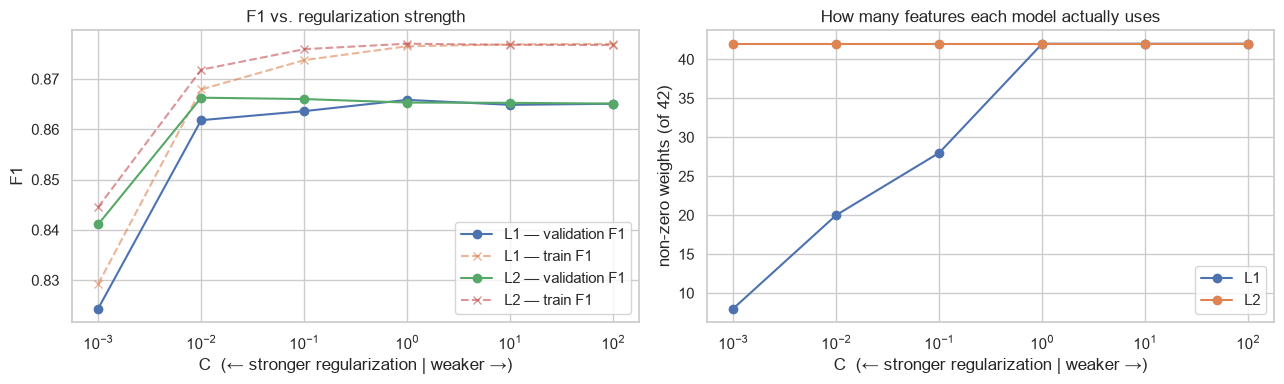

,penalty,C,train_f1,val_f1,val_recall,val_precision,nonzero_weights
0,L2,0.001,0.845,0.841,0.922,0.776,42
1,L2,0.010,0.872,0.866,0.865,0.871,42
2,L2,0.100,0.876,0.866,0.853,0.882,42
3,L2,1.000,0.877,0.865,0.852,0.882,42
4,L2,10.000,0.877,0.865,0.853,0.881,42
5,L2,100.000,0.877,0.865,0.853,0.881,42
6,L1,0.001,0.829,0.824,0.743,0.931,8
7,L1,0.010,0.868,0.862,0.839,0.889,20
8,L1,0.100,0.874,0.864,0.848,0.883,28
9,L1,1.000,0.877,0.866,0.853,0.883,42


In [5]:
C_values = [0.001, 0.01, 0.1, 1, 10, 100]
rows = []
for penalty, l1_ratio in [("L2", 0), ("L1", 1)]:
    for C in C_values:
        model = Pipeline([("scale", StandardScaler()),
                          ("clf", LogisticRegression(l1_ratio=l1_ratio, C=C, solver="liblinear", max_iter=2000))])
        r = cv_scores(model, f"{penalty}, C={C}")
        model.fit(X_train, y_train)
        r.update(penalty=penalty, C=C, nonzero_weights=int((model["clf"].coef_ != 0).sum()))
        rows.append(r)
reg_lr = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for penalty, d in reg_lr.groupby("penalty"):
    axes[0].plot(d["C"], d["val_f1"], marker="o", label=f"{penalty} — validation F1")
    axes[0].plot(d["C"], d["train_f1"], marker="x", linestyle="--", alpha=0.6, label=f"{penalty} — train F1")
    axes[1].plot(d["C"], d["nonzero_weights"], marker="o", label=penalty)
axes[0].set(xscale="log", xlabel="C  (← stronger regularization | weaker →)", ylabel="F1", title="F1 vs. regularization strength")
axes[1].set(xscale="log", xlabel="C  (← stronger regularization | weaker →)", ylabel="non-zero weights (of 42)",
            title="How many features each model actually uses")
axes[0].legend(); axes[1].legend()
plt.tight_layout(); plt.show()
reg_lr[["penalty", "C", "train_f1", "val_f1", "val_recall", "val_precision", "nonzero_weights"]].round(3)

**How to read this:**
- **Left:** with very strong regularization (C = 0.001) the model is too simple → lower F1 (**underfitting**). As C grows, F1 rises and then **levels off**.
  Train and validation curves stay close → logistic regression never overfits badly; regularization here is mainly about **stability and simplicity**.
- **Right:** **L1 switches features off** — at strong regularization it uses only a handful of the 42 features and still performs well.
  This tells us many features are **redundant** (as the correlation heatmap suggested). L2 always keeps all 42, just with smaller weights.

### 3b. Decision Tree: limiting depth

For trees, regularization means **limiting growth**:
- `max_depth` — maximum number of questions in a row
- `min_samples_leaf` — each final leaf must contain at least this many rows (prevents leaves built for 1–2 odd rows)

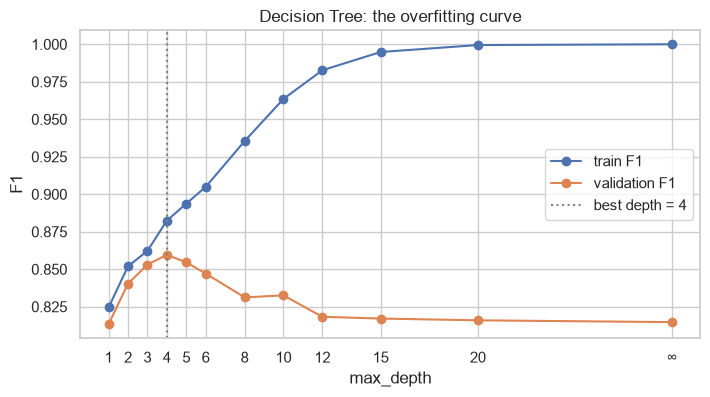

,model,train_f1,val_f1
0,depth=1,0.825,0.813
1,depth=2,0.852,0.840
2,depth=3,0.862,0.853
3,depth=4,0.882,0.860
4,depth=5,0.894,0.855
5,depth=6,0.905,0.847
6,depth=8,0.935,0.831
7,depth=10,0.964,0.833
8,depth=12,0.983,0.818
9,depth=15,0.995,0.817


In [6]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, None]
rows = []
for d in depths:
    r = cv_scores(DecisionTreeClassifier(max_depth=d, random_state=SEED), f"depth={d}")
    r["max_depth"] = 30 if d is None else d          # plot 'unlimited' at x = 30
    rows.append(r)
reg_tree = pd.DataFrame(rows)

plt.figure(figsize=(8, 4))
plt.plot(reg_tree["max_depth"], reg_tree["train_f1"], marker="o", label="train F1")
plt.plot(reg_tree["max_depth"], reg_tree["val_f1"], marker="o", label="validation F1")
best = reg_tree.loc[reg_tree["val_f1"].idxmax()]
plt.axvline(best["max_depth"], color="grey", linestyle=":", label=f"best depth = {int(best['max_depth'])}")
plt.xticks([1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 30], ["1", "2", "3", "4", "5", "6", "8", "10", "12", "15", "20", "∞"])
plt.xlabel("max_depth"); plt.ylabel("F1"); plt.title("Decision Tree: the overfitting curve"); plt.legend(); plt.show()
reg_tree[["model", "train_f1", "val_f1"]].round(3)

**This is the classic bias–variance picture:**
- **Shallow trees (left):** too simple, both scores low → **underfitting (high bias)**.
- **Deep trees (right):** train F1 → 1.0 while validation F1 **drops** → **overfitting (high variance)**.
- **The sweet spot** is in between, where validation F1 is highest. That is what regularization buys us.

## 4. Hyperparameter tuning with GridSearchCV

**Parameters vs. hyperparameters:**
- *Parameters* are **learned** from data (logistic-regression weights, the tree's split thresholds).
- *Hyperparameters* are **chosen by us** before training (C, penalty type, max_depth, …).

**GridSearchCV** tries every combination in a grid, scores each with the same engine-wise 5-fold cross-validation, and keeps the best (by F1).
Because selection uses only the training engines, the **test set stays untouched** for an honest final check.

We also tune **`class_weight`**: `"balanced"` makes mistakes on the rare "fails soon" class cost more (≈5.7× here), which usually **raises recall** at some cost in precision.

In [7]:
lr_pipe = Pipeline([("scale", StandardScaler()),
                    ("clf", LogisticRegression(solver="liblinear", max_iter=2000))])
lr_grid = {
    "clf__C": [0.001, 0.01, 0.1, 1, 10],
    "clf__l1_ratio": [0, 1],                  # 0 = L2, 1 = L1
    "clf__class_weight": [None, "balanced"],
}
lr_search = GridSearchCV(lr_pipe, lr_grid, cv=cv, scoring="f1")
lr_search.fit(X_train, y_train, groups=groups)

print("Best Logistic Regression settings:", lr_search.best_params_)
print(f"Best cross-validated F1: {lr_search.best_score_:.3f}")
lr_table = pd.DataFrame({
    "C": [p["clf__C"] for p in lr_search.cv_results_["params"]],
    "penalty": ["L1" if p["clf__l1_ratio"] == 1 else "L2" for p in lr_search.cv_results_["params"]],
    "class_weight": [str(p["clf__class_weight"]) for p in lr_search.cv_results_["params"]],
    "mean_val_f1": lr_search.cv_results_["mean_test_score"],
    "std_val_f1": lr_search.cv_results_["std_test_score"],
})
lr_table.sort_values("mean_val_f1", ascending=False).round(3)

Best Logistic Regression settings: {'clf__C': 0.01, 'clf__class_weight': None, 'clf__l1_ratio': 0}
Best cross-validated F1: 0.866


,C,penalty,class_weight,mean_val_f1,std_val_f1
4,0.010,L2,None,0.866,0.010
8,0.100,L2,None,0.866,0.012
13,1.000,L1,None,0.866,0.012
12,1.000,L2,None,0.865,0.011
16,10.000,L2,None,0.865,0.011
17,10.000,L1,None,0.865,0.011
9,0.100,L1,None,0.864,0.012
5,0.010,L1,None,0.862,0.012
0,0.001,L2,None,0.841,0.023
15,1.000,L1,balanced,0.830,0.031


Best Decision Tree settings: {'class_weight': None, 'max_depth': 5, 'min_samples_leaf': 50}
Best cross-validated F1: 0.859


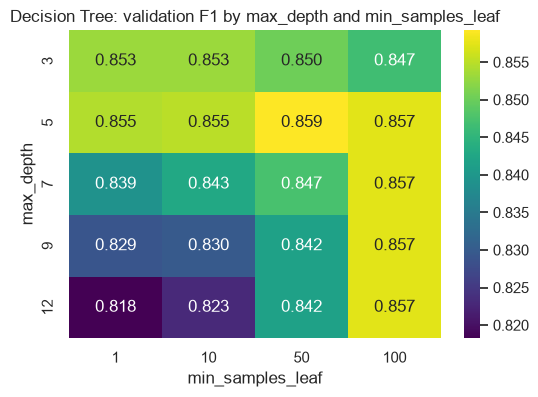

In [8]:
tree_grid = {
    "max_depth": [3, 5, 7, 9, 12],
    "min_samples_leaf": [1, 10, 50, 100],
    "class_weight": [None, "balanced"],
}
tree_search = GridSearchCV(DecisionTreeClassifier(random_state=SEED), tree_grid, cv=cv, scoring="f1")
tree_search.fit(X_train, y_train, groups=groups)

print("Best Decision Tree settings:", tree_search.best_params_)
print(f"Best cross-validated F1: {tree_search.best_score_:.3f}")

# Heatmap: effect of depth x leaf size (with the best class_weight)
best_cw = tree_search.best_params_["class_weight"]
params = tree_search.cv_results_["params"]
keep = [p["class_weight"] == best_cw for p in params]
cvr = pd.DataFrame({
    "max_depth": [p["max_depth"] for p in params],
    "min_samples_leaf": [p["min_samples_leaf"] for p in params],
    "mean_val_f1": tree_search.cv_results_["mean_test_score"],
})[keep]
pivot = cvr.pivot_table(index="max_depth", columns="min_samples_leaf", values="mean_val_f1")
plt.figure(figsize=(6, 4))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis")
plt.title("Decision Tree: validation F1 by max_depth and min_samples_leaf")
plt.xlabel("min_samples_leaf"); plt.ylabel("max_depth"); plt.show()

**Interpretation:**
- The best tree is **limited** (moderate depth + a minimum leaf size), not grown fully — the grid search confirms the regularization story.
- For logistic regression the top settings differ by only a few thousandths of F1, and the differences are smaller than the fold-to-fold `std` → the model is **not sensitive** to C once C ≥ 0.01. A moderately regularized model is chosen.
- **`class_weight="balanced"` did *not* win** for either model: it raises recall but lowers precision by more, so F1 drops. We will handle the "catch more failures" goal more directly in Notebook 5 by **tuning the decision threshold**.

## 5. Before vs. after: cross-validated comparison

In [9]:
lr_best = lr_search.best_estimator_
tree_best = tree_search.best_estimator_
results.append(cv_scores(lr_best, "Logistic Regression (tuned)"))
results.append(cv_scores(tree_best, "Decision Tree (tuned)"))
summary = pd.DataFrame(results).set_index("model")
summary[["train_f1", "val_f1", "val_recall", "val_precision", "val_roc_auc"]].round(3)

,train_f1,val_f1,val_recall,val_precision,val_roc_auc
model,,,,,
Logistic Regression (baseline),0.877,0.865,0.852,0.882,0.990
"Decision Tree (baseline, unlimited)",1.000,0.815,0.822,0.811,0.894
Logistic Regression (tuned),0.872,0.866,0.865,0.871,0.990
Decision Tree (tuned),0.885,0.859,0.848,0.872,0.982


**Interpretation:** tuning shrinks the tree's **train–validation gap** from 1.000 vs 0.815 to a small gap, and raises its validation F1 and ROC-AUC a lot — overfitting is under control.
Logistic regression barely changes — it was already well-behaved. Both tuned models now perform similarly in cross-validation.

## 6. What did the models learn? (interpretability)

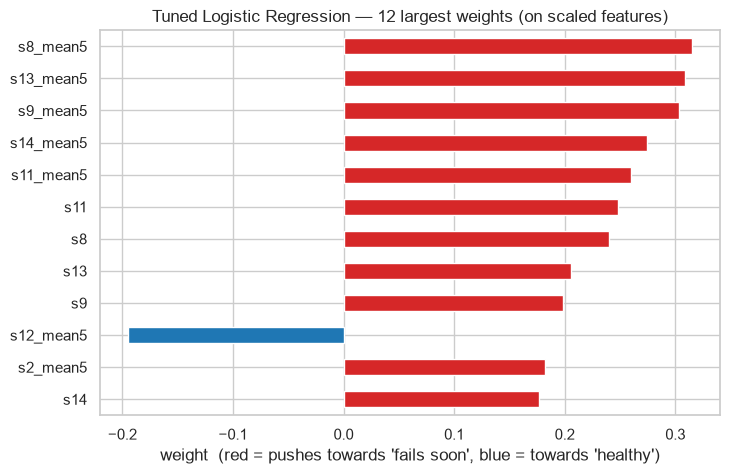

Non-zero weights: 42 of 42


In [10]:
coefs = pd.Series(lr_best["clf"].coef_[0], index=feature_cols)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(12)
plt.figure(figsize=(8, 5))
top[::-1].plot(kind="barh", color=["tab:red" if v > 0 else "tab:blue" for v in top[::-1]])
plt.title("Tuned Logistic Regression — 12 largest weights (on scaled features)")
plt.xlabel("weight  (red = pushes towards 'fails soon', blue = towards 'healthy')")
plt.show()
print(f"Non-zero weights: {(coefs != 0).sum()} of {len(coefs)}")

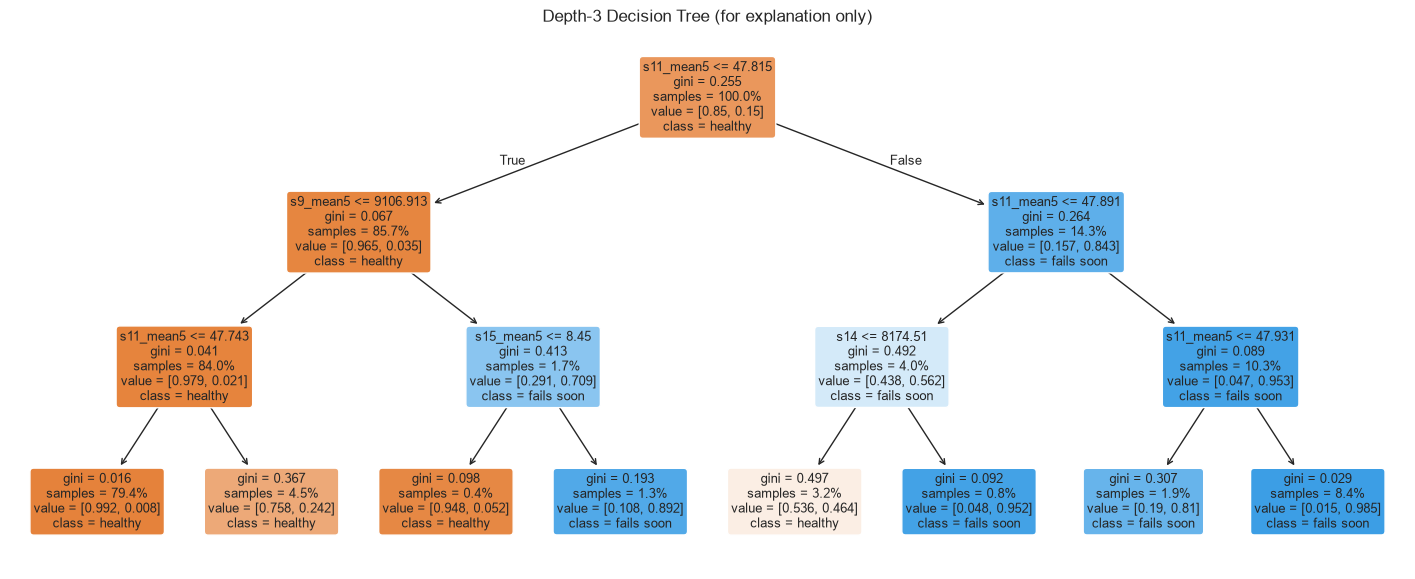

In [11]:
# A small depth-3 tree, drawn so it can be explained as a flowchart
small_tree = DecisionTreeClassifier(max_depth=3, class_weight=tree_search.best_params_["class_weight"],
                                    random_state=SEED).fit(X_train, y_train)
plt.figure(figsize=(18, 7))
plot_tree(small_tree, feature_names=feature_cols, class_names=["healthy", "fails soon"],
          filled=True, rounded=True, fontsize=9, impurity=True, proportion=True)
plt.title("Depth-3 Decision Tree (for explanation only)")
plt.show()

**Interpretation:**
- **Logistic regression:** the largest weights belong mostly to the **rolling-mean features** (`_mean5`) → the model relies on the **derived features** from Notebook 3 more than on raw readings.
  *Caution:* some of the biggest weights go to s8/s13 and s9/s14, which were only moderately correlated with RUL on their own. This is the **multicollinearity** effect: these sensors come in highly correlated pairs (s8 & s13: r = 0.83, s9 & s14: r = 0.96 — fan speed vs. corrected fan speed, core speed vs. corrected core speed), so the model splits and shifts weight between them. **Logistic-regression weights must be read with care when features are correlated** — that is exactly why we used L2 regularization, which keeps such weights small and stable.
- **Decision tree:** the very first question is **`s11_mean5`** — the rolling mean of the static pressure at the HPC outlet, the sensor most correlated with RUL in the EDA. This matches the physics: FD001's fault is **HPC degradation**.
  The tree reads like a maintenance rule: *"if the smoothed HPC-outlet pressure is above ≈47.8 psia → the engine very likely fails soon"* (84% of rows in that branch do).

## 7. Quick check on the test set (100 unseen engines)

===== Logistic Regression (tuned) =====
              precision    recall  f1-score   support

     healthy      0.990     0.996     0.993     12764
  fails soon      0.809     0.627     0.706       332

    accuracy                          0.987     13096
   macro avg      0.900     0.811     0.850     13096
weighted avg      0.986     0.987     0.986     13096

===== Decision Tree (tuned) =====
              precision    recall  f1-score   support

     healthy      0.991     0.993     0.992     12764
  fails soon      0.710     0.636     0.671       332

    accuracy                          0.984     13096
   macro avg      0.850     0.814     0.831     13096
weighted avg      0.983     0.984     0.984     13096



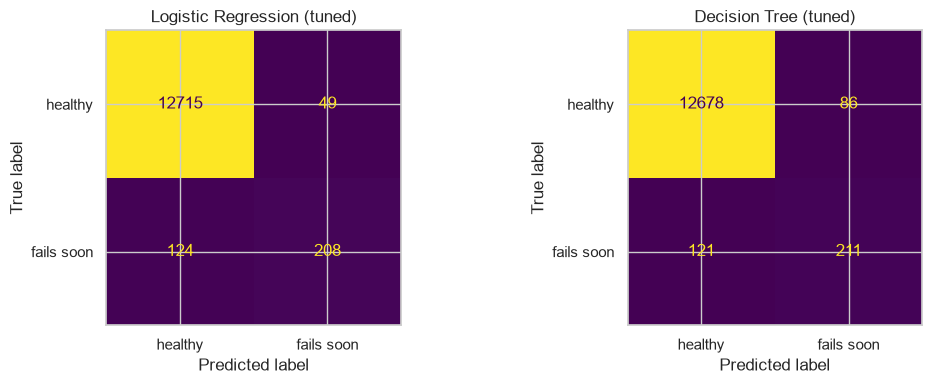

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, model) in zip(axes, [("Logistic Regression (tuned)", lr_best), ("Decision Tree (tuned)", tree_best)]):
    y_pred = model.predict(X_test)
    print(f"===== {name} =====")
    print(classification_report(y_test, y_pred, target_names=["healthy", "fails soon"], digits=3))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["healthy", "fails soon"], ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

**Interpretation:** on the 100 unseen test engines, **precision stays good but recall drops** compared with cross-validation (many "fails soon" rows are missed).
The test set is different: engines are cut off early, so its "fails soon" rows are mostly at **RUL 25–30, right next to the 30-cycle boundary**, where a failing engine looks almost identical to a healthy one.
We investigate this and fix it (with **threshold tuning**) in Notebook 5.

In [13]:
os.makedirs("../models", exist_ok=True)
joblib.dump(lr_best, "../models/logistic_regression.joblib")
joblib.dump(tree_best, "../models/decision_tree.joblib")
summary.to_csv("../models/cv_summary_nb4.csv")
print("Saved tuned models to ../models/")

Saved tuned models to ../models/


## Summary

| Model | What we learned |
|---|---|
| Logistic Regression | Strong, stable baseline; does not overfit. L1 shows many features are redundant. |
| Decision Tree (unlimited) | Memorises training engines → classic overfitting |
| Decision Tree (tuned) | Limiting depth / leaf size fixes most of the overfitting |

## Likely viva questions
- *Explain logistic regression in one sentence.* → A weighted sum of features passed through a sigmoid to give a probability of failure.
- *What is the difference between L1 and L2?* → L1 adds $\sum|w|$ and can set weights to exactly zero (feature selection); L2 adds $\sum w^2$ and shrinks all weights smoothly.
- *What does C do?* → Inverse regularization strength: smaller C = stronger penalty = simpler model.
- *How do you know the tree overfits?* → Train F1 = 1.0 but validation F1 is much lower; the gap shrinks after limiting depth.
- *Parameter vs. hyperparameter?* → Parameters are learned (weights, split thresholds); hyperparameters are set by us (C, max_depth) and tuned with cross-validation.
- *Why GroupKFold?* → So validation engines are never seen during training — same reason as the engine-wise test split.
- *What does class_weight="balanced" do?* → Makes errors on the rare class cost more, so the model doesn't ignore failing engines. (Here it lost on F1: recall went up but precision went down more.)
- *Why does s9 get a large weight if it was a weak sensor?* → Multicollinearity: s9 and s14 are nearly duplicates, so the linear model shifts weight between them; regularization keeps this under control.

**Next → Notebook 5: Ensemble (Random Forest) and final performance analysis.**